# Cross-Network Analysis

Three networks from one survey. This notebook holds the comparisons
between them.

Reads exported CSVs from `member_*/tables/` — run this after all three
member notebooks.

In [ ]:
import sys
from pathlib import Path

# This directory's own module. `common` needs no path work -- it is an
# installed package (pip install -e .), so it imports from any directory.
sys.path.insert(0, str(Path.cwd() / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from common import viz
import crosscheck as X

viz.apply_style()

FIG_DIR = Path.cwd() / 'figures'
TAB_DIR = Path.cwd() / 'tables'
print('Imports OK')

Imports OK


## 1. Assemble the per-statement comparison

Each member produced a different per-statement measure:

| | measure | meaning |
|---|---|---|
| A | `abs_gap` | how much it separates A's two student communities |
| B | `leverage` | how far a perturbation propagates through the signed network |
| C | `deviation_degree` | how many students answered it >1 SD from the class mean |

B's leverage is only defined on the giant component, so T08 and T09 (isolates)
don't have values — 58 of 60 statements remain for comparisons involving B.

In [ ]:
items = X.item_level_frame()
items.to_csv(TAB_DIR / 'table01_item_level_measures.csv', index=False)

print(f'{len(items)} statements, {items["leverage"].notna().sum()} with a leverage value')
print(f'missing leverage: {sorted(items.loc[items["leverage"].isna(), "item"])}')
items.head(8)

60 statements, 58 with a leverage value
missing leverage: ['T08', 'T09']


,item,block,abs_gap,deviation_degree,leverage
0,E01,E,0.338703,14,0.853589
1,E02,E,0.684098,38,0.415933
2,E03,E,0.388717,11,0.863597
3,E04,E,0.265425,42,0.340092
4,E05,E,0.495207,47,0.780940
5,E06,E,0.210298,32,0.462487
6,E07,E,0.948949,13,0.962335
7,E08,E,0.534624,15,0.813523


## 2. Do the three measures agree?

In [ ]:
corr = X.item_level_correlations(items)
corr.to_csv(TAB_DIR / 'table02_item_level_correlations.csv', index=False)

for _, r in corr.iterrows():
    print(f'{r["description_x"]}\n  vs {r["description_y"]}')
    print(f'  n = {r["n_items"]},  Pearson r = {r["pearson_r"]:+.3f} (p = {r["pearson_p"]:.2g}),'
          f'  Spearman rho = {r["spearman_rho"]:+.3f} (p = {r["spearman_p"]:.2g})\n')

A: separates the two student blocs
  vs B: dynamical leverage
  n = 58,  Pearson r = +0.617 (p = 2.6e-07),  Spearman rho = +0.784 (p = 3.5e-13)

B: dynamical leverage
  vs C: how many students deviate
  n = 58,  Pearson r = -0.369 (p = 0.0044),  Spearman rho = -0.390 (p = 0.0025)

A: separates the two student blocs
  vs C: how many students deviate
  n = 60,  Pearson r = -0.208 (p = 0.11),  Spearman rho = -0.349 (p = 0.0063)



**A and B agree strongly; C runs backwards against both.**

A statement that splits the class into two camps is almost always one whose
influence spreads furthest — but it's also one that individual students
deviate from *least*.

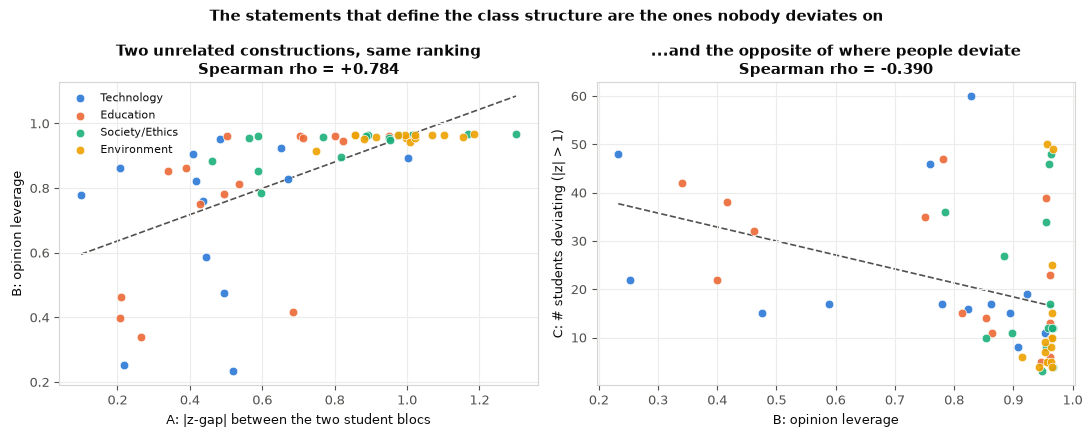

Saved fig01_item_level_crosscheck.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
sub = items.dropna(subset=['leverage'])

def scatter(ax, x, y, xlabel, ylabel, title):
    for blk in ['T', 'E', 'S', 'V']:
        d = sub[sub['block'] == blk]
        ax.scatter(d[x], d[y], s=38, color=viz.BLOCK_COLORS[blk],
                   label=viz.BLOCK_NAMES[blk], alpha=0.9, edgecolor='white', linewidth=0.5)
    # least-squares guide line, drawn as structure rather than as a series
    m, b = np.polyfit(sub[x], sub[y], 1)
    xs = np.linspace(sub[x].min(), sub[x].max(), 2)
    ax.plot(xs, m * xs + b, color=viz.INK_SOFT, lw=1.2, linestyle='--', zorder=0)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)

rho_ab = corr.loc[0, 'spearman_rho']
rho_bc = corr.loc[1, 'spearman_rho']

scatter(axes[0], 'abs_gap', 'leverage',
        "A: |z-gap| between the two student blocs",
        "B: opinion leverage",
        f'Two unrelated constructions, same ranking\nSpearman rho = {rho_ab:+.3f}')
scatter(axes[1], 'leverage', 'deviation_degree',
        "B: opinion leverage",
        "C: # students deviating (|z| > 1)",
        f'...and the opposite of where people deviate\nSpearman rho = {rho_bc:+.3f}')
axes[0].legend(fontsize=8, loc='upper left')

fig.suptitle('The statements that define the class structure are the ones nobody deviates on',
             fontweight='bold')
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig01_item_level_crosscheck.png')
plt.show()
print('Saved fig01_item_level_crosscheck.png')

## 3. Same picture at block level

In [ ]:
blocks = X.block_profile(items)
blocks.to_csv(TAB_DIR / 'table03_block_profile.csv', index=False)
print(blocks.to_string(index=False))

order_gap = ' > '.join(blocks.sort_values('mean_abs_gap', ascending=False)['block'])
order_lev = ' > '.join(blocks.sort_values('mean_leverage', ascending=False)['block'])
order_dev = ' > '.join(blocks.sort_values('mean_deviation_degree', ascending=False)['block'])
print(f'\nA  |z-gap|          ordering: {order_gap}')
print(f'B  leverage         ordering: {order_lev}')
print(f'C  deviation degree ordering: {order_dev}')
print(f'\nEnvironment leverage SD is '
      f'{blocks.set_index("block").loc["T","sd_leverage"] / blocks.set_index("block").loc["V","sd_leverage"]:.0f}x '
      f'smaller than Technology\'s.')

block  n_items  mean_abs_gap  mean_leverage  sd_leverage  mean_deviation_degree  rank_abs_gap  rank_leverage  rank_deviation
    T       15      0.434091       0.713813     0.248554              23.400000             4              4               1
    E       15      0.536159       0.761991     0.234850              23.133333             3              3               2
    S       15      0.834823       0.932562     0.053893              19.333333             2              2               3
    V       15      0.985648       0.957238     0.013631              14.133333             1              1               4

A  |z-gap|          ordering: V > S > E > T
B  leverage         ordering: V > S > E > T
C  deviation degree ordering: T > E > S > V

Environment leverage SD is 18x smaller than Technology's.


A and B give the same block ordering; C's is roughly the inverse.

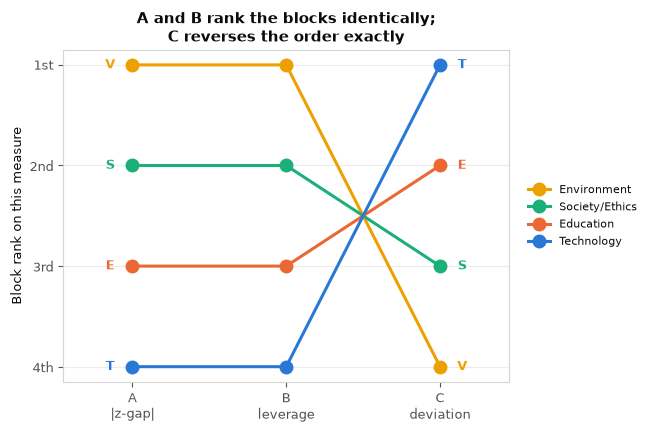

Saved fig02_block_inversion.png


In [ ]:
# Ranks, not scaled values: normalising each measure to its own maximum
# compresses both into the top of the axis and hides the reversal.
b = blocks.set_index('block')
measures = [('rank_abs_gap', 'A\n|z-gap|'),
            ('rank_leverage', 'B\nleverage'),
            ('rank_deviation', 'C\ndeviation')]

fig, ax = plt.subplots(figsize=(6.6, 4.4))
xs = np.arange(len(measures))
for blk in ['V', 'S', 'E', 'T']:
    ys = [b.loc[blk, m] for m, _ in measures]
    ax.plot(xs, ys, marker='o', ms=9, lw=2.2, color=viz.BLOCK_COLORS[blk],
            label=viz.BLOCK_NAMES[blk], zorder=3)
    ax.annotate(blk, (xs[0], ys[0]), xytext=(-16, 0), textcoords='offset points',
                va='center', ha='center', fontsize=9, color=viz.BLOCK_COLORS[blk],
                fontweight='bold')
    ax.annotate(blk, (xs[-1], ys[-1]), xytext=(16, 0), textcoords='offset points',
                va='center', ha='center', fontsize=9, color=viz.BLOCK_COLORS[blk],
                fontweight='bold')

ax.set_xticks(xs); ax.set_xticklabels([lab for _, lab in measures])
ax.set_yticks([1, 2, 3, 4]); ax.set_yticklabels(['1st', '2nd', '3rd', '4th'])
ax.invert_yaxis()
ax.set_xlim(-0.45, len(measures) - 0.55)
ax.set_ylabel('Block rank on this measure')
ax.set_title("A and B rank the blocks identically;\nC reverses the order exactly")
ax.grid(axis='x', visible=False)
ax.legend(fontsize=8, loc='center left', bbox_to_anchor=(1.02, 0.5))
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig02_block_inversion.png')
plt.show()
print('Saved fig02_block_inversion.png')

## 4. The three networks side by side

For the report. Everything here is read from the members' exported tables.

In [ ]:
comparison = X.network_comparison()
comparison.to_csv(TAB_DIR / 'table04_network_comparison.csv', index=False)
print(comparison.to_string(index=False))

                          network   owner  nodes edges   density modularity_Q Q_null_mean   Q_null_z
         A — agreement (students)  Vishal     87   822  0.219727      0.43205     0.17791  35.469817
            B — signed statements  Harith     60   402  0.227119         <NA>        <NA>       <NA>
          C — bipartite deviation Navneet    147  1200      <NA>         <NA>        <NA>       <NA>
C — student co-dissent projection Navneet     87  <NA>      <NA>     0.036787     0.05673  -6.140614


## 5. Student-level cross-check

Correlate A's pairwise agreement similarity against C's symmetrised MFPT
over all 3741 student pairs.

In [ ]:
pairs = X.member_table('C', 'table11_crosscheck_vs_agreement.csv')
print(pairs.to_string(index=False))
r = pairs.loc[0, 'pearson_r']
print(f'\nAgreement similarity explains {100 * r**2:.1f}% of the variance in '
      f'issue-mediated distance over {int(pairs.loc[0, "n_pairs"])} student pairs.')
print('The two networks measure genuinely different things about the same people.')

 n_pairs  pearson_r  pearson_p  spearman_rho  spearman_p
    3741   0.035923   0.028008      0.025876     0.11355

Agreement similarity explains 0.1% of the variance in issue-mediated distance over 3741 student pairs.
The two networks measure genuinely different things about the same people.
